### 3D Orbits ###

Processing SIDM_AHFout...
Processing CDM_AHFout...


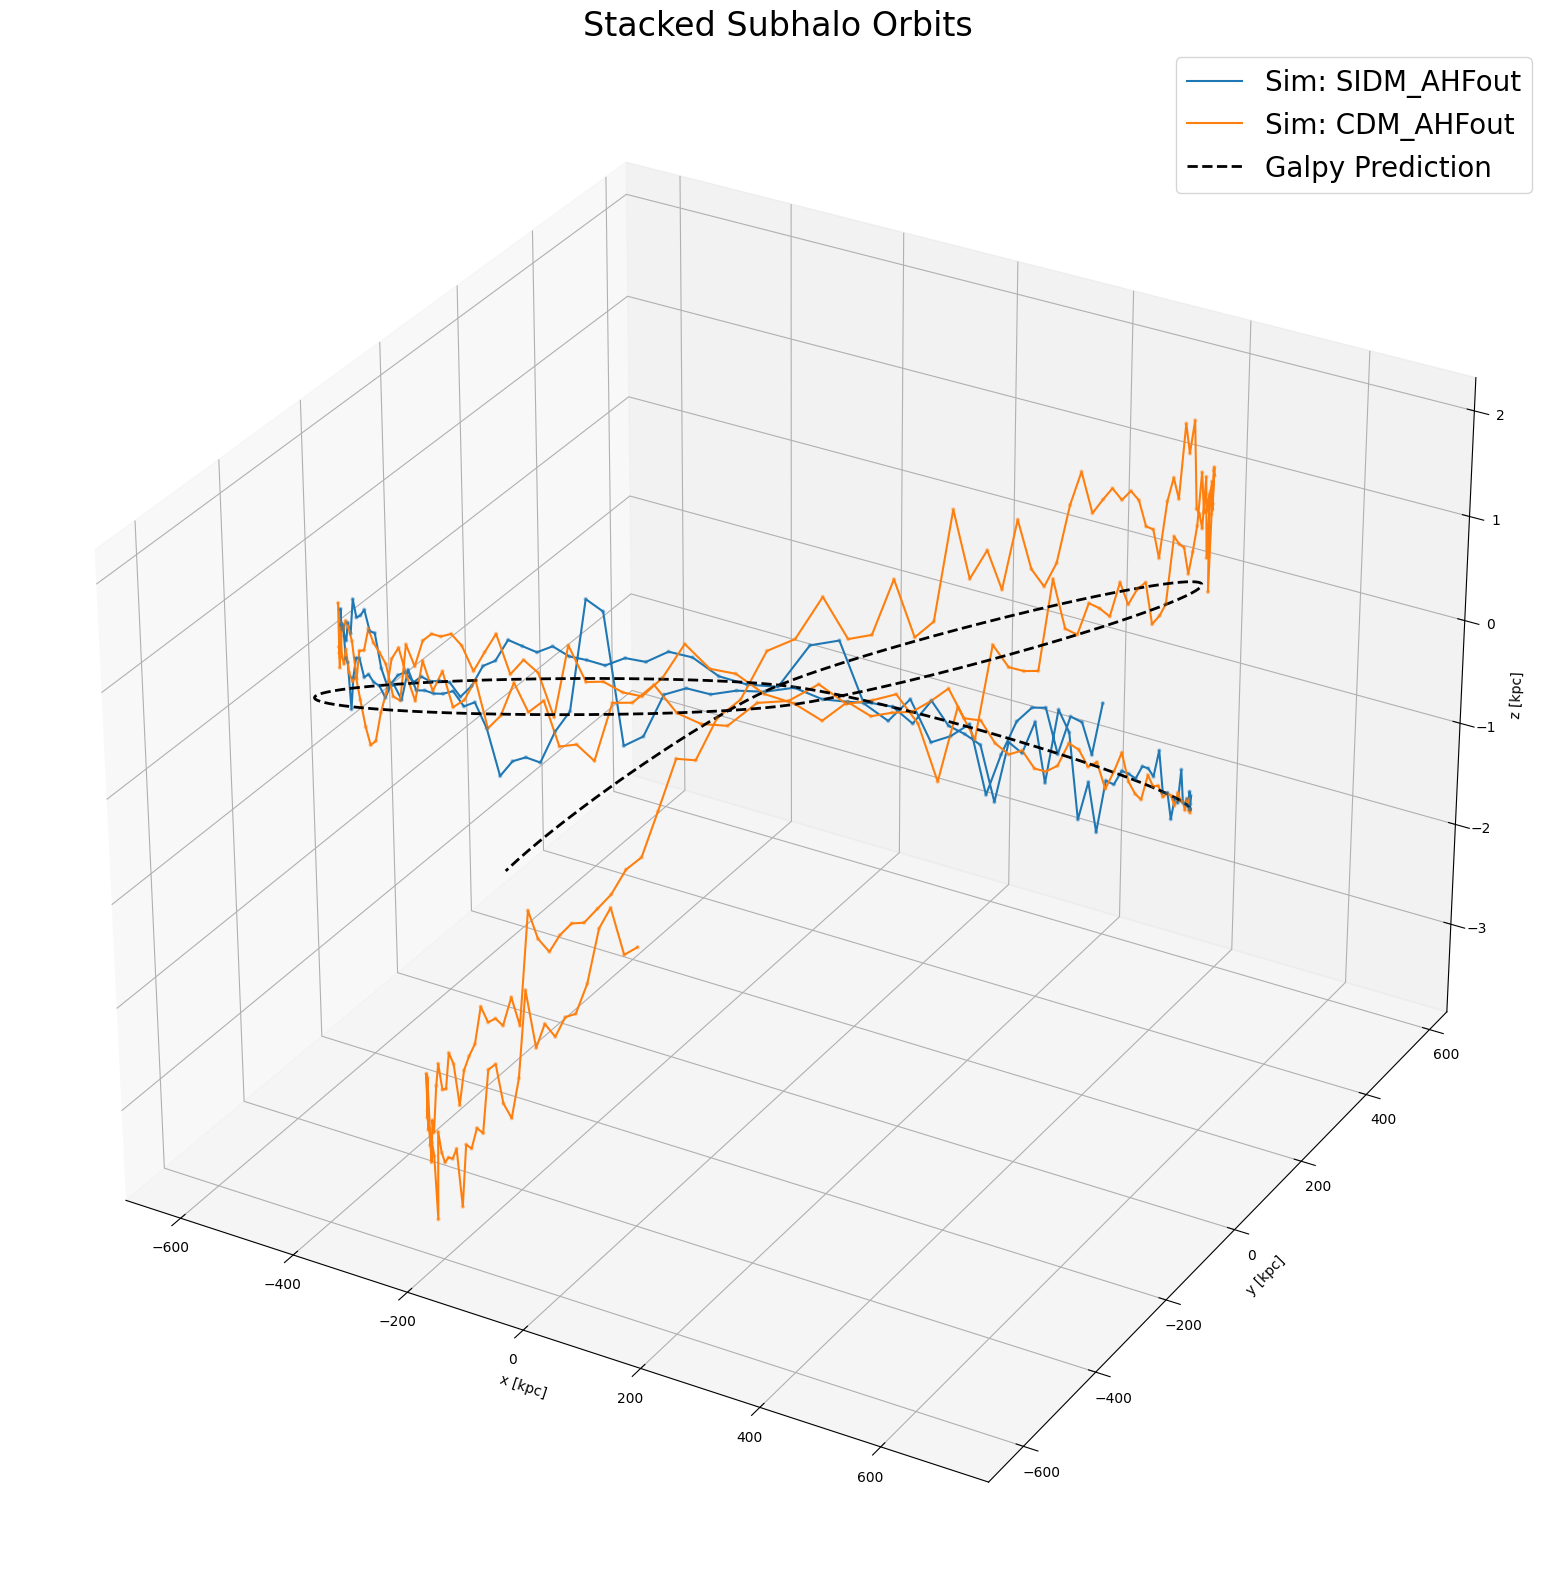

In [27]:
import os
import numpy as np
import matplotlib.pyplot as plt
from galpy.potential import NFWPotential
from galpy.orbit import Orbit

# ==================== CONFIG & CONSTANTS ====================
BASE_PATH = "./Data/"
# List your folder names here
FOLDERS = ["SIDM_AHFout", "CDM_AHFout"] 
TOTAL_SNAPS = 280
HOST_CENTER = np.array([10000.0, 10000.0, 10000.0])
TIME_BETWEEN_SNAPS_GYR = 0.05  # Gyr

# Galpy Params
RO_KPC, VO_KMS = 1.0, 220.0
T_UNIT_GYR = RO_KPC / (VO_KMS * 1.022712)
POT = NFWPotential(mvir=20.0, conc=6.5, ro=RO_KPC, vo=VO_KMS)

# ==================== HELPER FUNCTION ====================
def read_subhalo_AHF(folder_name):
    """Reads snapshot data from a specific folder."""
    coords = []
    radius = []
    mass = []

    ahf_dir = os.path.join(BASE_PATH, folder_name)
    
    for i in range(TOTAL_SNAPS + 1):
        path = os.path.join(ahf_dir, f"{i}-halos")
        if not os.path.exists(path): continue
        
        with open(path, 'r') as f:
            lines = f.readlines()
            for line in lines[1:]:
                cols = line.split()
    
                pos = np.array([float(cols[5]), float(cols[6]), float(cols[7])])
                coords.append(pos - HOST_CENTER)


                
                radius.append(float(cols[11]))

                mass.append(float(cols[3]))

    return np.array(coords), np.array(radius), np.array(mass)

# ==================== Process Data ====================
all_sims_pos = {}
all_sims_radius = {}
all_sims_mass = {}

for folder in FOLDERS:
    print(f"Processing {folder}...")
    pos_data = read_subhalo_AHF(folder)[0]
    radius_data = read_subhalo_AHF(folder)[1]
    mass_data = read_subhalo_AHF(folder)[2]

    if len(pos_data) > 0:
        all_sims_pos[folder] = pos_data
        all_sims_radius[folder] = radius_data
        all_sims_mass[folder] = mass_data

# ==================== Plot ====================
fig = plt.figure(figsize=(20, 16))
ax = fig.add_subplot(111, projection='3d')

# Loop through our stored data to plot each one
colors = ["blue", "green", "red"]  

time_steps = {}

for (name, coords), color in zip(all_sims_pos.items(), colors):
    ax.plot(coords[:,0], coords[:,1], coords[:,2], label=f'Sim: {name}', lw=1.5)
    ax.scatter(coords[:,0], coords[:,1], coords[:,2], s=5, alpha=0.3)
    time_steps[name] = np.arange(coords.shape[0]) * TIME_BETWEEN_SNAPS_GYR

CDM_time_steps = time_steps.get("CDM_AHFout", None)
SIDM_time_steps = time_steps.get("SIDM_AHFout", None)

# ==================== Galpy prediction ====================
orb = Orbit([0.7*974.4/RO_KPC, 0.0/VO_KMS, 33.15/VO_KMS, 0.0, 0.0, 0.0], ro=RO_KPC, vo=VO_KMS)
t_galpy = np.linspace(0, 14.0/T_UNIT_GYR, 500)
t_galpy_gyr = t_galpy * T_UNIT_GYR
orb.integrate(t_galpy, POT)
ax.plot(orb.x(t_galpy)*RO_KPC, orb.y(t_galpy)*RO_KPC, orb.z(t_galpy)*RO_KPC, 
        'black', label='Galpy Prediction', lw=2, ls='--')

ax.set_title("Stacked Subhalo Orbits", fontsize=24)
ax.set_xlabel("x [kpc]"); ax.set_ylabel("y [kpc]"); ax.set_zlabel("z [kpc]")
ax.legend(loc='upper right', prop={'size': 20})
plt.tight_layout()
plt.show()

## x, y, z plots ## 

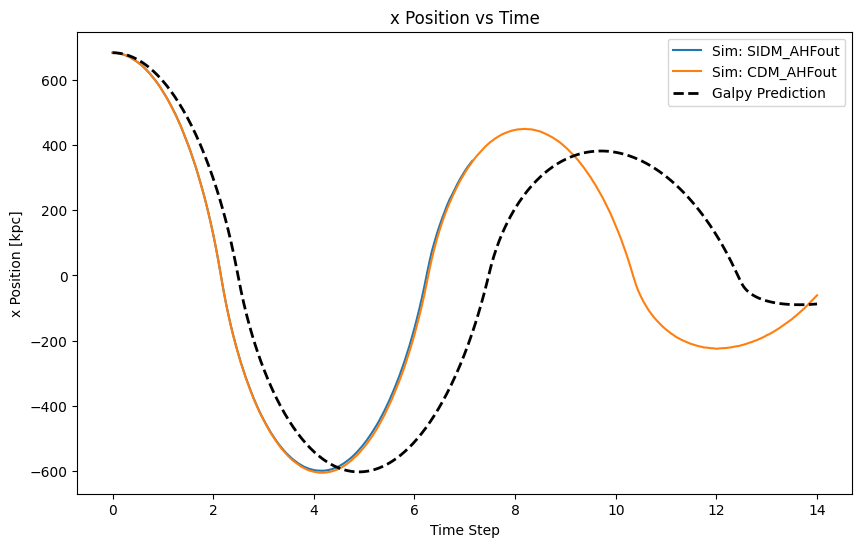

In [28]:
# Plot x vs time for each simulation
plt.figure(figsize=(10, 6))
for name, coords in all_sims_pos.items():
    time_steps = np.arange(coords.shape[0]) * TIME_BETWEEN_SNAPS_GYR
    plt.plot(time_steps, coords[:,0], label=f'Sim: {name}')

# Add Galpy prediction for x vs time
plt.plot(t_galpy_gyr, orb.x(t_galpy), label='Galpy Prediction', color='black', lw=2, ls='--')
plt.title("x Position vs Time")
plt.xlabel("Time Step")
plt.ylabel("x Position [kpc]")
plt.legend()
plt.show()

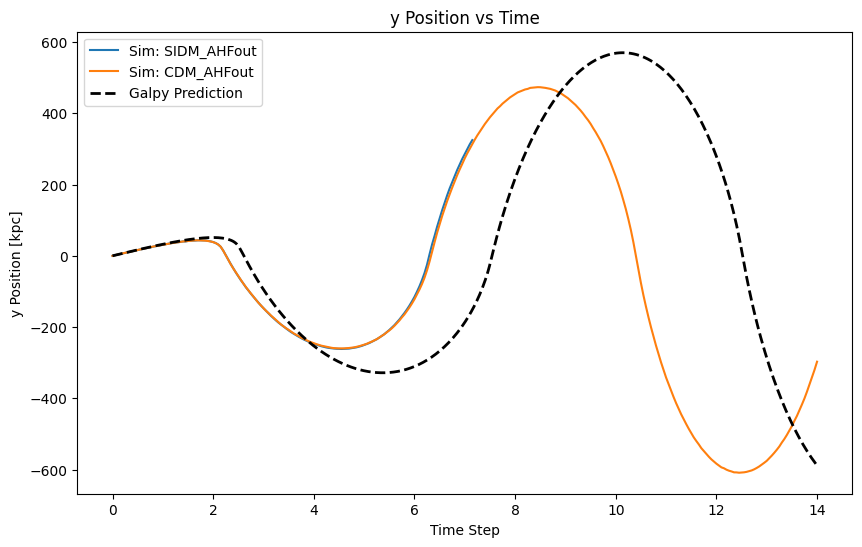

In [29]:
# Plot y vs time for each simulation
plt.figure(figsize=(10, 6))
for name, coords in all_sims_pos.items():
    time_steps = np.arange(coords.shape[0]) * TIME_BETWEEN_SNAPS_GYR
    plt.plot(time_steps, coords[:,1], label=f'Sim: {name}')

# Add Galpy prediction for y vs time
plt.plot(t_galpy_gyr, orb.y(t_galpy), label='Galpy Prediction', color='black', lw=2, ls='--')
plt.title("y Position vs Time")
plt.xlabel("Time Step")
plt.ylabel("y Position [kpc]")
plt.legend()
plt.show()

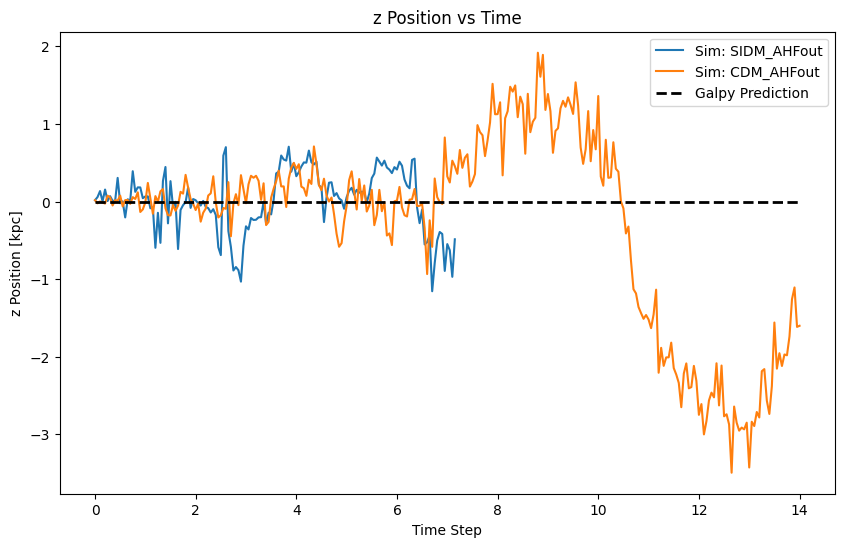

In [30]:
# Plot z vs time for each simulation
# plt.figure(figsize=(10, 6))
# for name, coords in all_sims_pos.items():
#     plt.plot(time_steps[name], coords[:,2], label=f'Sim: {name}')

# # Add Galpy prediction for z vs time
# plt.plot(t_galpy_gyr, orb.z(t_galpy), label='Galpy Prediction', color='black', lw=2, ls='--')
# plt.title("z Position vs Time")
# plt.xlabel("Time Step")
# plt.ylabel("z Position [kpc]")
# plt.legend()
# plt.show()

# Plot z vs time for each simulation
plt.figure(figsize=(10, 6))
for name, coords in all_sims_pos.items():
    time_steps = np.arange(coords.shape[0]) * TIME_BETWEEN_SNAPS_GYR
    plt.plot(time_steps, coords[:,2], label=f'Sim: {name}')

# Add Galpy prediction for z vs time
plt.plot(t_galpy_gyr, orb.z(t_galpy), label='Galpy Prediction', color='black', lw=2, ls='--')
plt.title("z Position vs Time")
plt.xlabel("Time Step")
plt.ylabel("z Position [kpc]")
plt.legend()
plt.show()

## Orbital distance ##

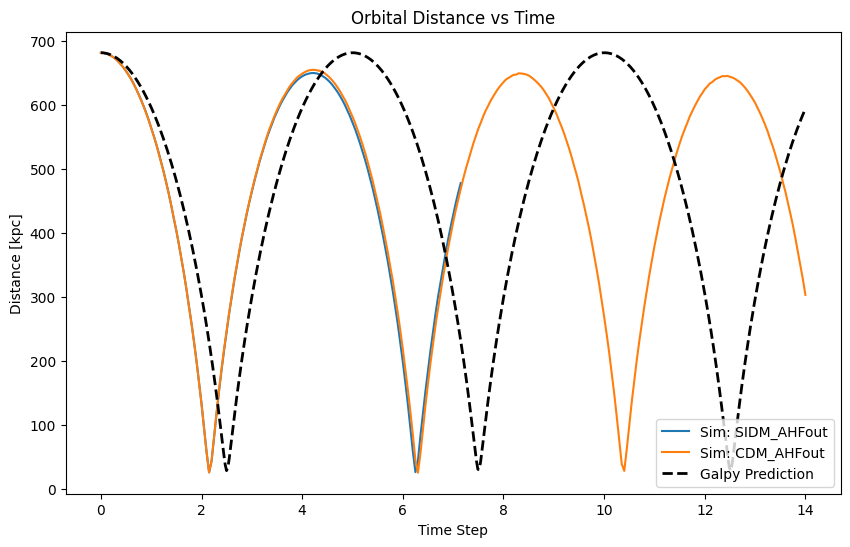

In [31]:
# Orbital distance vs time for each simulation
distance = {}
plt.figure(figsize=(10, 6))
for name, coords in all_sims_pos.items():
    distance[name] = np.linalg.norm(coords, axis=1)
    time_steps = np.arange(coords.shape[0]) * TIME_BETWEEN_SNAPS_GYR
    plt.plot(time_steps, distance[name], label=f'Sim: {name}')

distance_CDM = distance["CDM_AHFout"]
distance_SIDM = distance["SIDM_AHFout"]

# Add Galpy prediction for orbital distance vs time
galpy_distance = np.sqrt(orb.x(t_galpy)**2 + orb.y(t_galpy)**2 + orb.z(t_galpy)**2) * RO_KPC
plt.plot(t_galpy_gyr, galpy_distance, label='Galpy Prediction', color='black', lw=2, ls='--')
plt.title("Orbital Distance vs Time")
plt.xlabel("Time Step")
plt.ylabel("Distance [kpc]")
plt.legend()
plt.show()

## Period and Apo/Peri-center ##

In [32]:
from scipy.signal import find_peaks

print("pericenter, apocenter, period")

# ---------------------------------------------------CDM---------------------------------------------------

# Calculate Period and Apo/Peri-center for each simulation

CDM_apo = []
CDM_apo_idx = []
CDM_peri = []
CDM_peri_idx = []

for i in range(1, len(distance_CDM) - 1):
    # use find_peaks to find local minimum/maxima (apo-centers)
    CDM_apo_peaks, _ = find_peaks(distance_CDM) # indices of local maxima (apo-centers)
    CDM_peri_peaks, _ = find_peaks(-distance_CDM) # indices of local minima (peri-centers)

CDM_apo = distance_CDM[CDM_apo_peaks]
CDM_peri = distance_CDM[CDM_peri_peaks]

CDM_peri = CDM_peri[:-1]  # Remove the last element

CDM_peri_mean = np.mean(CDM_peri)
CDM_apo_mean = np.mean(CDM_apo)
CDM_period_apo = (CDM_apo_peaks[1] - CDM_apo_peaks[0]) * TIME_BETWEEN_SNAPS_GYR
CDM_period_peri = (CDM_peri_peaks[1] - CDM_peri_peaks[0]) * TIME_BETWEEN_SNAPS_GYR
CDM_period_mean = (CDM_period_apo + CDM_period_peri) / 2

print(CDM_peri_mean, CDM_apo_mean, CDM_period_mean)

# ---------------------------------------------------SIDM---------------------------------------------------

SIDM_apo = []
SIDM_apo_idx = []
SIDM_peri = []
SIDM_peri_idx = []

for i in range(1, len(distance_SIDM) - 1):
    # use find_peaks to find local minimum/maxima (apo-centers)
    SIDM_apo_peaks, _ = find_peaks(distance_SIDM) # indices of local maxima (apo-centers)
    SIDM_peri_peaks, _ = find_peaks(-distance_SIDM) # indices of local minima (peri-centers)

SIDM_apo = distance_SIDM[SIDM_apo_peaks]
SIDM_peri = distance_SIDM[SIDM_peri_peaks]

SIDM_peri = SIDM_peri[:-1]  # Remove the last element

SIDM_peri_mean = np.mean(SIDM_peri)
SIDM_apo_mean = np.mean(SIDM_apo)
SIDM_period_peri = (SIDM_peri_peaks[1] - SIDM_peri_peaks[0]) * TIME_BETWEEN_SNAPS_GYR

print(SIDM_peri_mean, SIDM_apo_mean, SIDM_period_peri)

# ---------------------------------------------------galpy---------------------------------------------------
# Galpy orbital parameters
galpy_period = orb.Tr(pot=POT) #radial period
galpy_apo = np.max(galpy_distance)
galpy_peri = np.min(galpy_distance)
np.seterr(divide='ignore', invalid='ignore')

print(galpy_peri, galpy_apo, galpy_period)

pericenter, apocenter, period
26.13190909601253 649.1069339415722 4.1
25.554135948180736 650.3851425930889 4.1000000000000005
28.21364990453169 682.0799999999999 5.003645471909799


## Mass loss ##

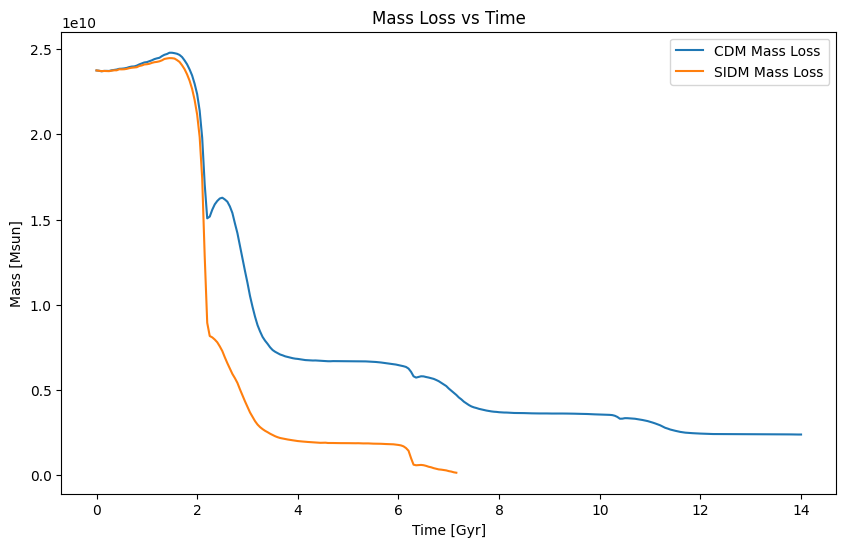

In [33]:
# mass loss evolution for CDM and SIDM
plt.figure(figsize=(10, 6))
plt.plot(CDM_time_steps, all_sims_mass["CDM_AHFout"], label='CDM Mass Loss')
plt.plot(SIDM_time_steps, all_sims_mass["SIDM_AHFout"], label='SIDM Mass Loss')
plt.title("Mass Loss vs Time")
plt.xlabel("Time [Gyr]")
plt.ylabel("Mass [Msun]")
plt.legend()

## subhalo radius evolution ##

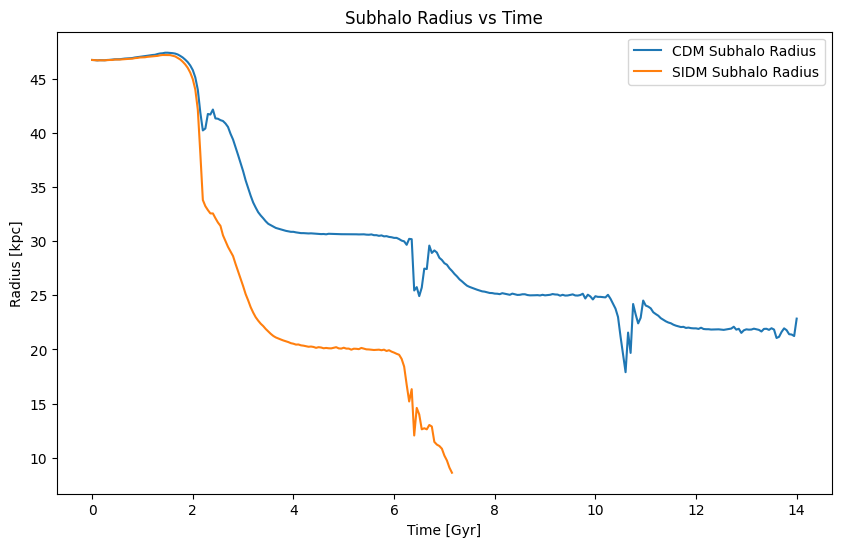

In [34]:
# subhalo radius for CDM and SIDM
plt.figure(figsize=(10, 6))
plt.plot(CDM_time_steps, all_sims_radius["CDM_AHFout"], label='CDM Subhalo Radius')
plt.plot(SIDM_time_steps, all_sims_radius["SIDM_AHFout"], label='SIDM Subhalo Radius')
plt.title("Subhalo Radius vs Time")
plt.xlabel("Time [Gyr]")
plt.ylabel("Radius [kpc]")
plt.legend()

## CDM Density profile ## 

281 valid AHF centers collected.
{0: array([10682.10081878,  9999.93722797, 10000.01734354]), 1: array([10681.76325586, 10001.70234229,  9999.9768719 ]), 2: array([10680.95493902, 10003.39301817, 10000.00084653]), 3: array([10679.54554558, 10005.0271074 ,  9999.98630087]), 4: array([10677.43475592, 10006.74624561,  9999.97382747]), 5: array([10674.79522006, 10008.33686676, 10000.07598493]), 6: array([10671.7887073 , 10009.83515243, 10000.05374455]), 7: array([10667.92435116, 10011.54432694,  9999.94914105]), 8: array([10663.48548581, 10013.11965222, 10000.01729394]), 9: array([10658.79765838, 10014.92437421, 10000.01021188]), 10: array([10653.14118109, 10016.33811491, 10000.07619512]), 11: array([10647.22196635, 10017.81232217,  9999.93721457]), 12: array([10640.2729941 , 10019.44080694, 10000.01818457]), 13: array([10632.83878999, 10021.1844407 , 10000.02001878]), 14: array([10625.22101189, 10022.58403456,  9999.97043503]), 15: array([10616.47270676, 10024.25626109, 10000.05701297]), 

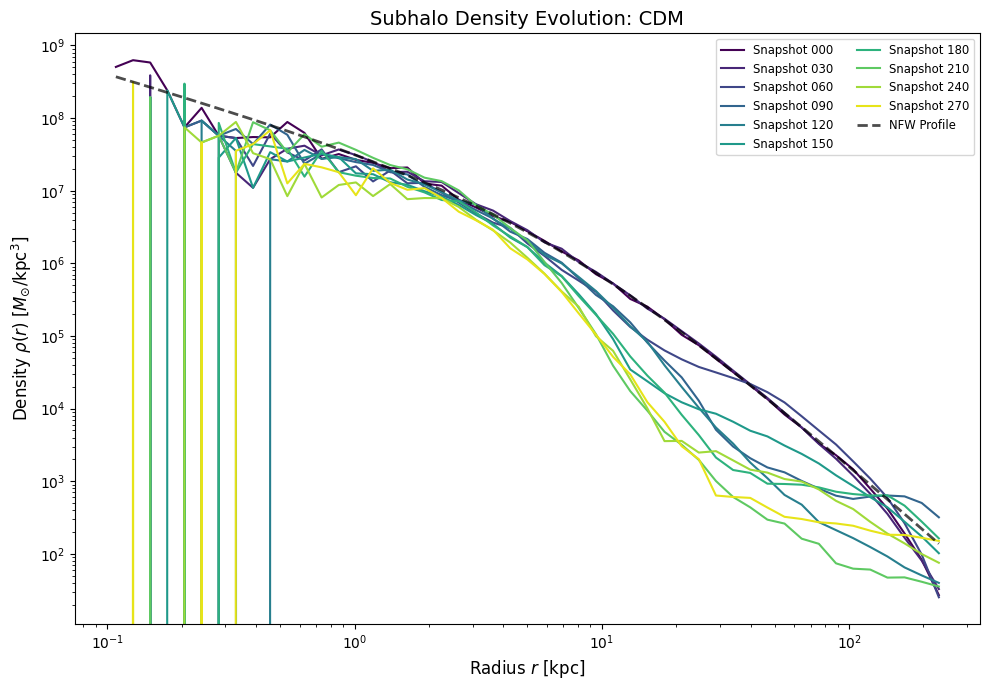

In [35]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt

# ==================== CONFIGURATION ====================
AHF_DIR = "./Data/CDM_AHFout/"
SNAP_DIR = "./Data/CDM/"
SNAPSHOT_INTERVAL = 1
TOTAL_SNAPS = 280

# Fixed Radial Grid Parameters
R_MIN, R_MAX, N_BINS = 0.1, 250.0, 50

# ==================== 1. PRE-COLLECT CENTERS ====================
print("Collecting AHF centers...")
all_centers_CDM = {}
# Loop through potential snapshot range to find valid subhalo entries
for i in range(TOTAL_SNAPS + 1):
    path = os.path.join(AHF_DIR, f"{i}-halos")
    if os.path.exists(path):
        with open(path, 'r') as f:
            lines = f.readlines()
            if len(lines) > 1:
                # Assuming index 1 is the first subhalo in the AHF file
                cols = lines[1].split()
                raw_pos = np.array([float(cols[5]), float(cols[6]), float(cols[7])])
                all_centers_CDM[i] = raw_pos
print(len(all_centers_CDM), "valid AHF centers collected.")
print(all_centers_CDM)

aval_snap = np.linspace(0, len(all_centers_CDM)-1, len(all_centers_CDM), dtype=int)

# Filter indices based on your interval within the valid subhalo lifetime
indices_to_process = [i for i in aval_snap if i % SNAPSHOT_INTERVAL == 0]
print(indices_to_process)

# ==================== 2. SETUP GRID & FUNCTIONS ====================
bins = np.logspace(np.log10(R_MIN), np.log10(R_MAX), N_BINS)
bin_centers = np.sqrt(bins[1:] * bins[:-1])  # Geometric mean for log-bins
v_shells = (4/3) * np.pi * (bins[1:]**3 - bins[:-1]**3)

def calc_density(pos, mass, center):
    """Calculates density profile for a single snapshot."""
    r = np.sqrt(np.sum((pos - center)**2, axis=1))
    mass_in_bin, _ = np.histogram(r, bins=bins, weights=mass)
    return mass_in_bin / v_shells

# ==================== 3. MAIN PROCESSING LOOP ====================
CDM_density_list = []
CDM_processed_snaps = []

print(f"Processing {len(indices_to_process)} snapshots...")
for i in indices_to_process:
    snap_path = os.path.join(SNAP_DIR, f"snapshot_{i:03d}.hdf5")
    
    if os.path.exists(snap_path):
        with h5py.File(snap_path, 'r') as f:
            # Adjust PartType1 if your particles are in a different group
            pos = f['PartType1/Coordinates'][:]
            mass = f['PartType1/Masses'][:] #e10 Msun
            CDM_mass_Msun = mass * 1e10 # Convert to Msun
            
        rho = calc_density(pos, CDM_mass_Msun,  all_centers_CDM[i])
        CDM_density_list.append(rho)
        CDM_processed_snaps.append(i)
        print(f"  Snapshot {i:03d} completed.", end='\r')

        if i==0:
            rho_CDM_first = rho  # Store the first snapshot's density for later comparison
        if i==280:
            rho_CDM_last = rho  # Store the last snapshot's density for later comparison

# ==================== 4. PLOTTING ====================
plt.figure(figsize=(10, 7))
cmap = plt.get_cmap('viridis')

# plot with certain interval
plot_interval = 30
for idx, rho in enumerate(CDM_density_list):
    snap_num = CDM_processed_snaps[idx]
    # Color scale normalized to the full simulation duration
    color = cmap(snap_num / TOTAL_SNAPS)
    if snap_num % plot_interval == 0:
        plt.loglog(bin_centers, rho, label=f'Snapshot {snap_num:03d}', color=color, lw=1.5)

# Add NFW reference line for comparison
rs = 6.58383 # kpc
rhos = 6302800 # Msun/kpc^3
nfw_profile = rhos / ((bin_centers/rs) * (1 + bin_centers/rs)**2)
plt.loglog(bin_centers, nfw_profile, '--', label='NFW Profile', color='black', lw=2, alpha=0.7)

plt.xlabel(r'Radius $r$ [kpc]', fontsize=12)
plt.ylabel(r'Density $\rho(r)$ [$M_{\odot}/\mathrm{kpc}^3$]', fontsize=12)
plt.title(f'Subhalo Density Evolution: {SNAP_DIR.split("/")[-2]}', fontsize=14)
plt.legend(ncol=2, fontsize='small', loc='upper right')
plt.tight_layout()
plt.show()

## SIDM Density Profile ##

144 valid AHF centers collected.
{0: array([10682.10081878,  9999.93722797, 10000.01734354]), 1: array([10681.84387835, 10001.65550392, 10000.05705259]), 2: array([10681.05745575, 10003.29689271, 10000.13462011]), 3: array([10679.52914383, 10005.13314294, 10000.00083628]), 4: array([10677.46567964, 10006.56800809, 10000.15439781]), 5: array([10675.02482002, 10008.19126765, 10000.00650785]), 6: array([10671.78133691, 10009.86849121, 10000.06885418]), 7: array([10668.10755059, 10011.53601954, 10000.00939704]), 8: array([10663.48253764, 10013.11479471, 10000.00851582]), 9: array([10658.4581307 , 10014.98634222, 10000.30442836]), 10: array([10653.12258343, 10016.5125016 ,  9999.97776391]), 11: array([10647.01968413, 10018.21552004, 10000.00128268]), 12: array([10640.8561321 , 10019.54682849,  9999.79537996]), 13: array([10633.54048636, 10021.00583795, 10000.0285096 ]), 14: array([10625.32049417, 10022.13842135, 10000.01016259]), 15: array([10616.77737887, 10023.78466139, 10000.39060432]), 

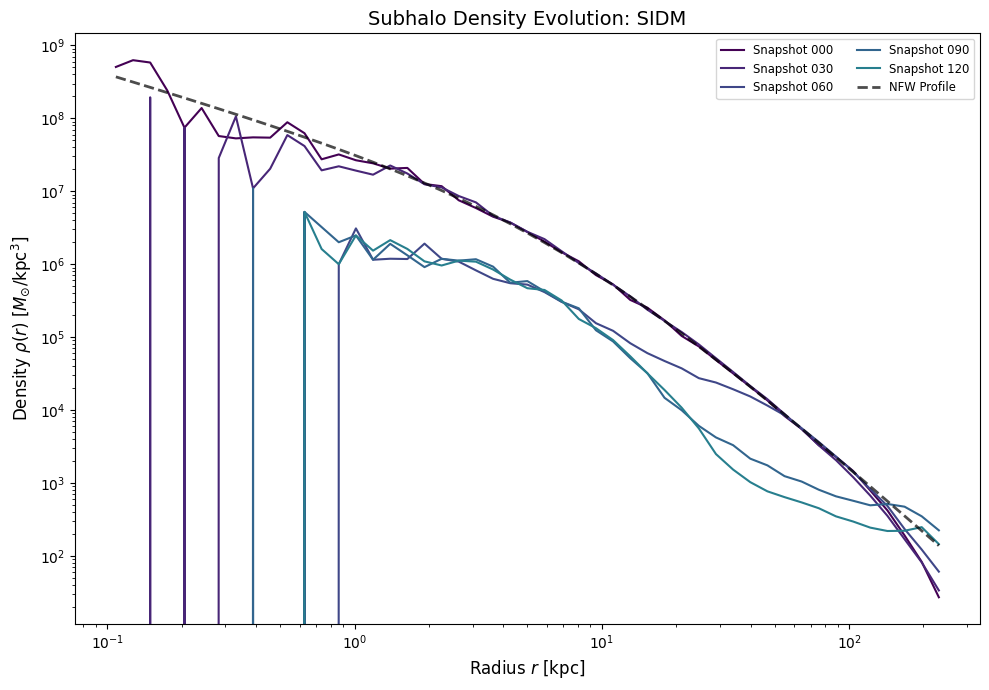

In [36]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt

# ==================== CONFIGURATION ====================
AHF_DIR = "./Data/SIDM_AHFout/"
SNAP_DIR = "./Data/SIDM/"
SNAPSHOT_INTERVAL = 1
TOTAL_SNAPS = 280

# Fixed Radial Grid Parameters
R_MIN, R_MAX, N_BINS = 0.1, 250.0, 50

# ==================== 1. PRE-COLLECT CENTERS ====================
print("Collecting AHF centers...")
all_centers_SIDM = {}
# Loop through potential snapshot range to find valid subhalo entries
for i in range(TOTAL_SNAPS + 1):
    path = os.path.join(AHF_DIR, f"{i}-halos")
    if os.path.exists(path):
        with open(path, 'r') as f:
            lines = f.readlines()
            if len(lines) > 1:
                # Assuming index 1 is the first subhalo in the AHF file
                cols = lines[1].split()
                raw_pos = np.array([float(cols[5]), float(cols[6]), float(cols[7])])
                all_centers_SIDM[i] = raw_pos
print(len(all_centers_SIDM), "valid AHF centers collected.")
print(all_centers_SIDM)

aval_snap = np.linspace(0, len(all_centers_SIDM)-1, len(all_centers_SIDM), dtype=int)

# Filter indices based on your interval within the valid subhalo lifetime
indices_to_process = [i for i in aval_snap if i % SNAPSHOT_INTERVAL == 0]
print(indices_to_process)

# ==================== 2. SETUP GRID & FUNCTIONS ====================
bins = np.logspace(np.log10(R_MIN), np.log10(R_MAX), N_BINS)
bin_centers = np.sqrt(bins[1:] * bins[:-1])  # Geometric mean for log-bins
v_shells = (4/3) * np.pi * (bins[1:]**3 - bins[:-1]**3)

def calc_density(pos, mass, center):
    """Calculates density profile for a single snapshot."""
    r = np.sqrt(np.sum((pos - center)**2, axis=1))
    mass_in_bin, _ = np.histogram(r, bins=bins, weights=mass)
    return mass_in_bin / v_shells

# ==================== 3. MAIN PROCESSING LOOP ====================
SIDM_density_list = []
SIDM_processed_snaps = []

print(f"Processing {len(indices_to_process)} snapshots...")
for i in indices_to_process:
    snap_path = os.path.join(SNAP_DIR, f"snapshot_{i:03d}.hdf5")
    
    if os.path.exists(snap_path):
        with h5py.File(snap_path, 'r') as f:
            # Adjust PartType1 if your particles are in a different group
            pos = f['PartType1/Coordinates'][:]
            mass = f['PartType1/Masses'][:] #e10 Msun
            SIDM_mass_Msun = mass * 1e10 # Convert to Msun
            
        rho = calc_density(pos, SIDM_mass_Msun, all_centers_SIDM[i])
        SIDM_density_list.append(rho)
        SIDM_processed_snaps.append(i)
        print(f"  Snapshot {i:03d} completed.", end='\r')

        if i==0:
            rho_SIDM_first = rho  # Store the first snapshot's density for later comparison
        if i==143:
            rho_SIDM_last = rho  # Store the last snapshot's density for later comparison

# ==================== 4. PLOTTING ====================
plt.figure(figsize=(10, 7))
cmap = plt.get_cmap('viridis')

# plot with certain interval
plot_interval = 30
for idx, rho in enumerate(SIDM_density_list):
    snap_num = SIDM_processed_snaps[idx]
    # Color scale normalized to the full simulation duration
    color = cmap(snap_num / TOTAL_SNAPS)
    if snap_num % plot_interval == 0:
        plt.loglog(bin_centers, rho, label=f'Snapshot {snap_num:03d}', color=color, lw=1.5)

# Add NFW reference line for comparison
rs = 6.58383 # kpc
rhos = 6302800 # Msun/kpc^3
nfw_profile = rhos / ((bin_centers/rs) * (1 + bin_centers/rs)**2)
plt.loglog(bin_centers, nfw_profile, '--', label='NFW Profile', color='black', lw=2, alpha=0.7)

plt.xlabel(r'Radius $r$ [kpc]', fontsize=12)
plt.ylabel(r'Density $\rho(r)$ [$M_{\odot}/\mathrm{kpc}^3$]', fontsize=12)
plt.title(f'Subhalo Density Evolution: {SNAP_DIR.split("/")[-2]}', fontsize=14)
plt.legend(ncol=2, fontsize='small', loc='upper right')
plt.tight_layout()
plt.show()

## Stack first and last snapshot - Density profile ##

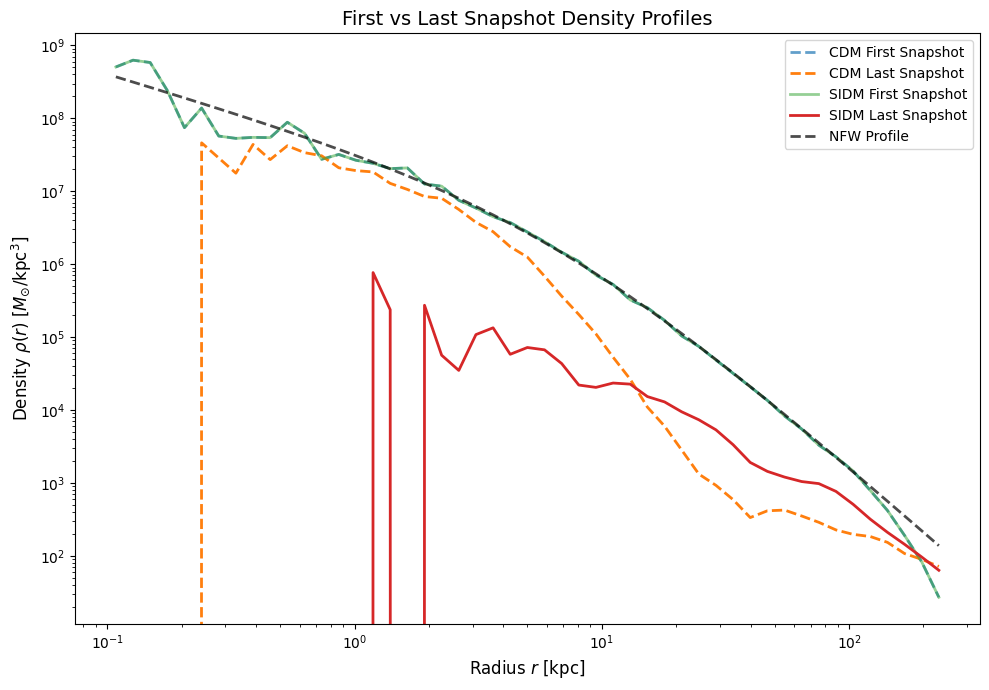

In [37]:
# plot first and last snapshot density profile for comparison for both CDM and SIDM

# get first and last AHF centers for CDM and SIDM
centers_CDM = [all_centers_CDM[0], all_centers_CDM[280]]
centers_SIDM = [all_centers_SIDM[0], all_centers_SIDM[143]]

# Plotting
plt.figure(figsize=(10, 7))
plt.loglog(bin_centers, rho_CDM_first, label='CDM First Snapshot', lw=2, alpha=0.7, ls='--')
plt.loglog(bin_centers, rho_CDM_last, label='CDM Last Snapshot', lw=2, ls='--')
plt.loglog(bin_centers, rho_SIDM_first, label='SIDM First Snapshot', lw=2, alpha=0.5)
plt.loglog(bin_centers, rho_SIDM_last, label='SIDM Last Snapshot', lw=2)

# Add NFW reference line for comparison
rs = 6.58383 # kpc
rhos = 6302800 # Msun/kpc^3
nfw_profile = rhos / ((bin_centers/rs) * (1 + bin_centers/rs)**2)
plt.loglog(bin_centers, nfw_profile, '--', label='NFW Profile', color='black', lw=2, alpha=0.7)

plt.xlabel(r'Radius $r$ [kpc]', fontsize=12)
plt.ylabel(r'Density $\rho(r)$ [$M_{\odot}/\mathrm{kpc}^3$]', fontsize=12)
plt.title('First vs Last Snapshot Density Profiles', fontsize=14)
plt.legend()
plt.tight_layout()
plt.show()

## CDM velocity dispersion ##

In [38]:
# velocity dispersion calculator (use np.std)
def calc_velocity_dispersion(pos, vel, center):
    """Calculates velocity dispersion profile for a single snapshot."""
    r = np.sqrt(np.sum((pos - center)**2, axis=1))
    vel_dispersion = np.zeros(len(bin_centers))
    
    for i in range(len(bin_centers)):
        in_bin = (r >= bins[i]) & (r < bins[i+1])
        if np.sum(in_bin) > 0:
            vel_dispersion[i] = np.std(vel[in_bin], axis=0).mean()  # Average over x,y,z components
    
    return vel_dispersion

281 valid AHF centers collected.
{0: array([10682.10081878,  9999.93722797, 10000.01734354]), 1: array([10681.76325586, 10001.70234229,  9999.9768719 ]), 2: array([10680.95493902, 10003.39301817, 10000.00084653]), 3: array([10679.54554558, 10005.0271074 ,  9999.98630087]), 4: array([10677.43475592, 10006.74624561,  9999.97382747]), 5: array([10674.79522006, 10008.33686676, 10000.07598493]), 6: array([10671.7887073 , 10009.83515243, 10000.05374455]), 7: array([10667.92435116, 10011.54432694,  9999.94914105]), 8: array([10663.48548581, 10013.11965222, 10000.01729394]), 9: array([10658.79765838, 10014.92437421, 10000.01021188]), 10: array([10653.14118109, 10016.33811491, 10000.07619512]), 11: array([10647.22196635, 10017.81232217,  9999.93721457]), 12: array([10640.2729941 , 10019.44080694, 10000.01818457]), 13: array([10632.83878999, 10021.1844407 , 10000.02001878]), 14: array([10625.22101189, 10022.58403456,  9999.97043503]), 15: array([10616.47270676, 10024.25626109, 10000.05701297]), 

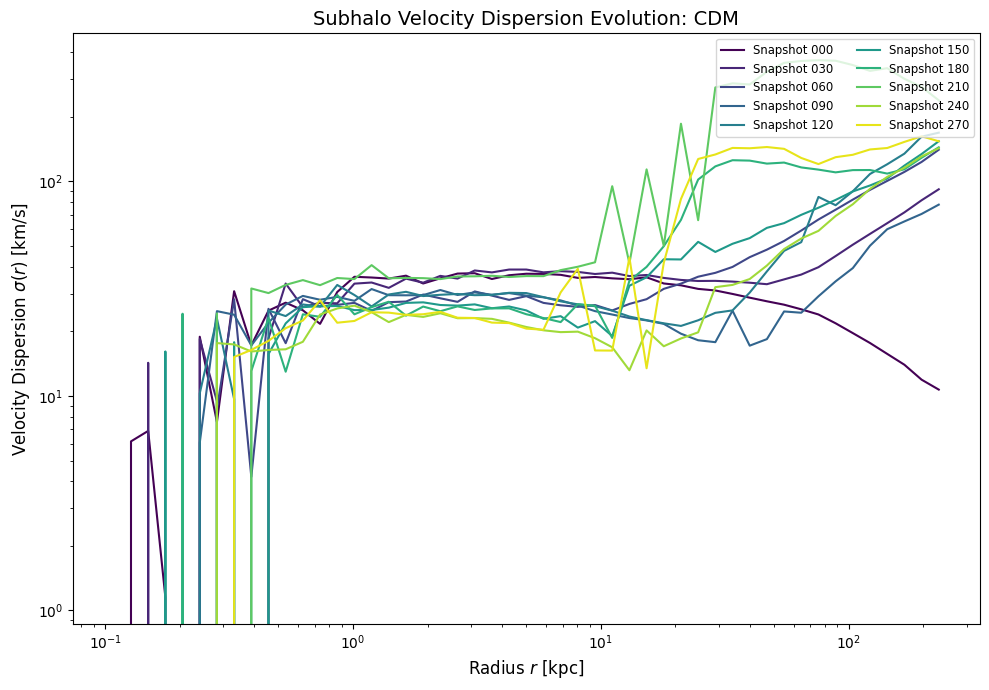

In [39]:
# CDM velocity dispersion profile evolution

import os
import h5py
import numpy as np
import matplotlib.pyplot as plt

# ==================== CONFIGURATION ====================
AHF_DIR = "./Data/CDM_AHFout/"
SNAP_DIR = "./Data/CDM/"
SNAPSHOT_INTERVAL = 1
TOTAL_SNAPS = 280

# Fixed Radial Grid Parameters
R_MIN, R_MAX, N_BINS = 0.1, 250.0, 50

# ==================== 1. PRE-COLLECT CENTERS ====================
print("Collecting AHF centers...")
all_centers_CDM = {}
# Loop through potential snapshot range to find valid subhalo entries
for i in range(TOTAL_SNAPS + 1):
    path = os.path.join(AHF_DIR, f"{i}-halos")
    if os.path.exists(path):
        with open(path, 'r') as f:
            lines = f.readlines()
            if len(lines) > 1:
                # Assuming index 1 is the first subhalo in the AHF file
                cols = lines[1].split()
                raw_pos = np.array([float(cols[5]), float(cols[6]), float(cols[7])])
                all_centers_CDM[i] = raw_pos
print(len(all_centers_CDM), "valid AHF centers collected.")
print(all_centers_CDM)

aval_snap = np.linspace(0, len(all_centers_CDM)-1, len(all_centers_CDM), dtype=int)

# Filter indices based on your interval within the valid subhalo lifetime
indices_to_process = [i for i in aval_snap if i % SNAPSHOT_INTERVAL == 0]
print(indices_to_process)

# ==================== 2. SETUP GRID & FUNCTIONS ====================
bins = np.logspace(np.log10(R_MIN), np.log10(R_MAX), N_BINS)
bin_centers = np.sqrt(bins[1:] * bins[:-1])  # Geometric mean for log-bins

# ==================== 3. MAIN PROCESSING LOOP ====================
CDM_vel_disp_list = []
CDM_processed_snaps = []

print(f"Processing {len(indices_to_process)} snapshots...")
for i in indices_to_process:
    snap_path = os.path.join(SNAP_DIR, f"snapshot_{i:03d}.hdf5")
    
    if os.path.exists(snap_path):
        with h5py.File(snap_path, 'r') as f:
            # Adjust PartType1 if your particles are in a different group
            pos = f['PartType1/Coordinates'][:]
            vel = f['PartType1/Velocities'][:] # km/s
            
        vel_disp = calc_velocity_dispersion(pos, vel, all_centers_CDM[i])
        CDM_vel_disp_list.append(vel_disp)
        CDM_processed_snaps.append(i)
        print(f"  Snapshot {i:03d} completed.", end='\r')

        if i==0:
            vel_disp_CDM_first = vel_disp  # Store the first snapshot's velocity dispersion for later comparison
        if i==280:
            vel_disp_CDM_last = vel_disp  # Store the last snapshot's velocity dispersion for later comparison

# ==================== 4. PLOTTING ====================
plt.figure(figsize=(10, 7))
cmap = plt.get_cmap('viridis')

# plot with certain interval
plot_interval = 30
for idx, vel_disp in enumerate(CDM_vel_disp_list):
    snap_num = CDM_processed_snaps[idx]
    # Color scale normalized to the full simulation duration
    color = cmap(snap_num / TOTAL_SNAPS)
    if snap_num % plot_interval == 0:
        plt.loglog(bin_centers, vel_disp, label=f'Snapshot {snap_num:03d}', color=color, lw=1.5)
        
plt.xlabel(r'Radius $r$ [kpc]', fontsize=12)
plt.ylabel(r'Velocity Dispersion $\sigma(r)$ [km/s]', fontsize=12)
plt.title(f'Subhalo Velocity Dispersion Evolution: {SNAP_DIR.split("/")[-2]}', fontsize=14)
plt.legend(ncol=2, fontsize='small', loc='upper right')
plt.tight_layout()
plt.show()

## SIDM velocity dispersion ##

144 valid AHF centers collected.
{0: array([10682.10081878,  9999.93722797, 10000.01734354]), 1: array([10681.84387835, 10001.65550392, 10000.05705259]), 2: array([10681.05745575, 10003.29689271, 10000.13462011]), 3: array([10679.52914383, 10005.13314294, 10000.00083628]), 4: array([10677.46567964, 10006.56800809, 10000.15439781]), 5: array([10675.02482002, 10008.19126765, 10000.00650785]), 6: array([10671.78133691, 10009.86849121, 10000.06885418]), 7: array([10668.10755059, 10011.53601954, 10000.00939704]), 8: array([10663.48253764, 10013.11479471, 10000.00851582]), 9: array([10658.4581307 , 10014.98634222, 10000.30442836]), 10: array([10653.12258343, 10016.5125016 ,  9999.97776391]), 11: array([10647.01968413, 10018.21552004, 10000.00128268]), 12: array([10640.8561321 , 10019.54682849,  9999.79537996]), 13: array([10633.54048636, 10021.00583795, 10000.0285096 ]), 14: array([10625.32049417, 10022.13842135, 10000.01016259]), 15: array([10616.77737887, 10023.78466139, 10000.39060432]), 

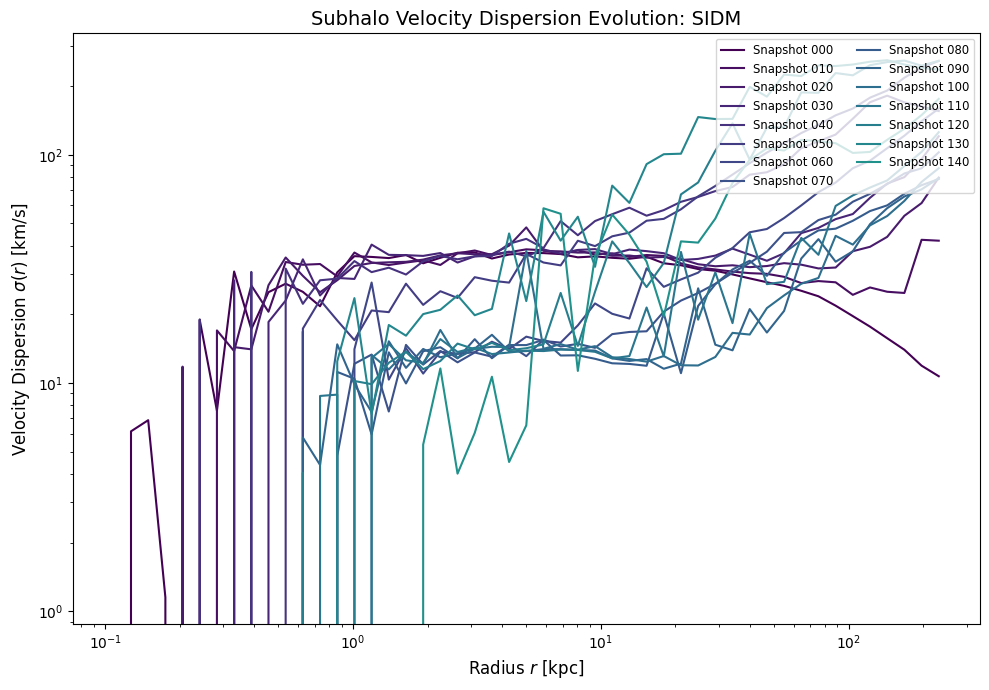

In [40]:
# SIDM velocity dispersion profile evolution

import os
import h5py
import numpy as np
import matplotlib.pyplot as plt

# ==================== CONFIGURATION ====================
AHF_DIR = "./Data/SIDM_AHFout/"
SNAP_DIR = "./Data/SIDM/"
SNAPSHOT_INTERVAL = 1
TOTAL_SNAPS = 280

# Fixed Radial Grid Parameters
R_MIN, R_MAX, N_BINS = 0.1, 250.0, 50

# ==================== 1. PRE-COLLECT CENTERS ====================
print("Collecting AHF centers...")
all_centers_SIDM = {}
# Loop through potential snapshot range to find valid subhalo entries
for i in range(TOTAL_SNAPS + 1):
    path = os.path.join(AHF_DIR, f"{i}-halos")
    if os.path.exists(path):
        with open(path, 'r') as f:
            lines = f.readlines()
            if len(lines) > 1:
                # Assuming index 1 is the first subhalo in the AHF file
                cols = lines[1].split()
                raw_pos = np.array([float(cols[5]), float(cols[6]), float(cols[7])])
                all_centers_SIDM[i] = raw_pos
print(len(all_centers_SIDM), "valid AHF centers collected.")
print(all_centers_SIDM)

aval_snap = np.linspace(0, len(all_centers_SIDM)-1, len(all_centers_SIDM), dtype=int)

# Filter indices based on your interval within the valid subhalo lifetime
indices_to_process = [i for i in aval_snap if i % SNAPSHOT_INTERVAL == 0]
print(indices_to_process)

# ==================== 2. SETUP GRID & FUNCTIONS ====================
bins = np.logspace(np.log10(R_MIN), np.log10(R_MAX), N_BINS)
bin_centers = np.sqrt(bins[1:] * bins[:-1])  # Geometric mean for log-bins

# ==================== 3. MAIN PROCESSING LOOP ====================
SIDM_vel_disp_list = []
SIDM_processed_snaps = []

print(f"Processing {len(indices_to_process)} snapshots...")
for i in indices_to_process:
    snap_path = os.path.join(SNAP_DIR, f"snapshot_{i:03d}.hdf5")
    
    if os.path.exists(snap_path):
        with h5py.File(snap_path, 'r') as f:
            # Adjust PartType1 if your particles are in a different group
            pos = f['PartType1/Coordinates'][:]
            vel = f['PartType1/Velocities'][:] # km/s
            
        vel_disp = calc_velocity_dispersion(pos, vel, all_centers_SIDM[i])
        SIDM_vel_disp_list.append(vel_disp)
        SIDM_processed_snaps.append(i)
        print(f"  Snapshot {i:03d} completed.", end='\r')

        if i==0:
            vel_disp_SIDM_first = vel_disp  # Store the first snapshot's velocity dispersion for later comparison
        if i==143:
            vel_disp_SIDM_last = vel_disp  # Store the last snapshot's velocity dispersion for later comparison

# ==================== 4. PLOTTING ====================
plt.figure(figsize=(10, 7))
cmap = plt.get_cmap('viridis')

# plot with certain interval
plot_interval = 10
for idx, vel_disp in enumerate(SIDM_vel_disp_list):
    snap_num = SIDM_processed_snaps[idx]
    # Color scale normalized to the full simulation duration
    color = cmap(snap_num / TOTAL_SNAPS)
    if snap_num % plot_interval == 0:
        plt.loglog(bin_centers, vel_disp, label=f'Snapshot {snap_num:03d}', color=color, lw=1.5)
        
plt.xlabel(r'Radius $r$ [kpc]', fontsize=12)
plt.ylabel(r'Velocity Dispersion $\sigma(r)$ [km/s]', fontsize=12)
plt.title(f'Subhalo Velocity Dispersion Evolution: {SNAP_DIR.split("/")[-2]}', fontsize=14)
plt.legend(ncol=2, fontsize='small', loc='upper right')
plt.tight_layout()
plt.show()

## Stack first and last snapshot - Velocity dispersion ##

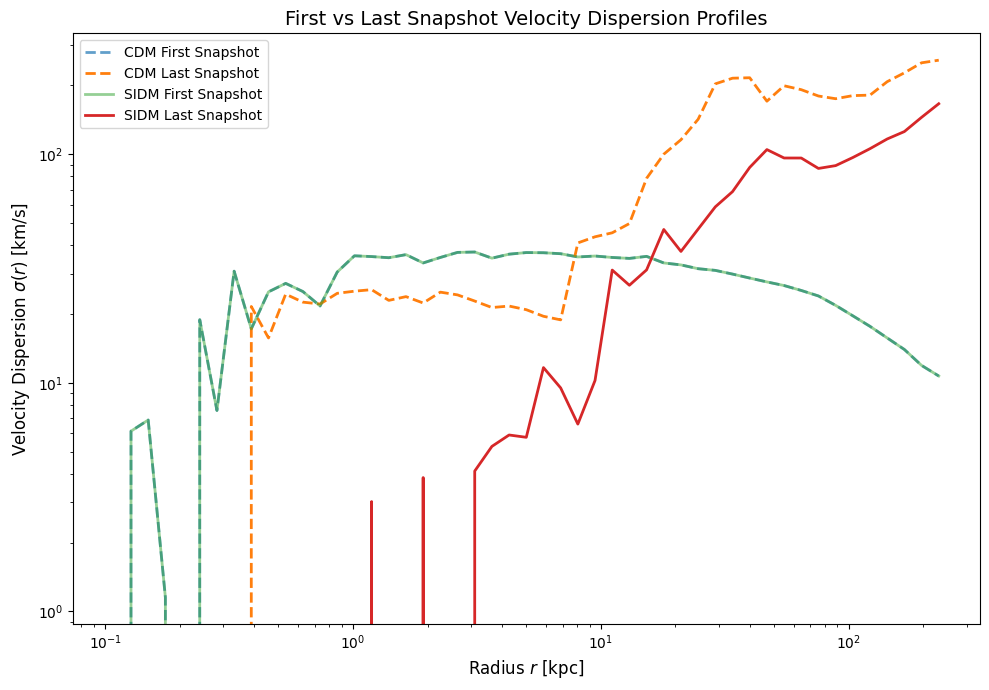

In [41]:
# plot first and last snapshot density profile for comparison for both CDM and SIDM

# get first and last AHF centers for CDM and SIDM
centers_CDM = [all_centers_CDM[0], all_centers_CDM[280]]
centers_SIDM = [all_centers_SIDM[0], all_centers_SIDM[143]]

# Plotting
plt.figure(figsize=(10, 7))
plt.loglog(bin_centers, vel_disp_CDM_first, label='CDM First Snapshot', lw=2, alpha=0.7, ls='--')
plt.loglog(bin_centers, vel_disp_CDM_last, label='CDM Last Snapshot', lw=2, ls='--')
plt.loglog(bin_centers, vel_disp_SIDM_first, label='SIDM First Snapshot', lw=2, alpha=0.5)
plt.loglog(bin_centers, vel_disp_SIDM_last, label='SIDM Last Snapshot', lw=2)

plt.xlabel(r'Radius $r$ [kpc]', fontsize=12)
plt.ylabel(r'Velocity Dispersion $\sigma(r)$ [km/s]', fontsize=12)
plt.title('First vs Last Snapshot Velocity Dispersion Profiles', fontsize=14)
plt.legend()
plt.tight_layout()
plt.show()

## CDM - Velocity distribution evolution ##

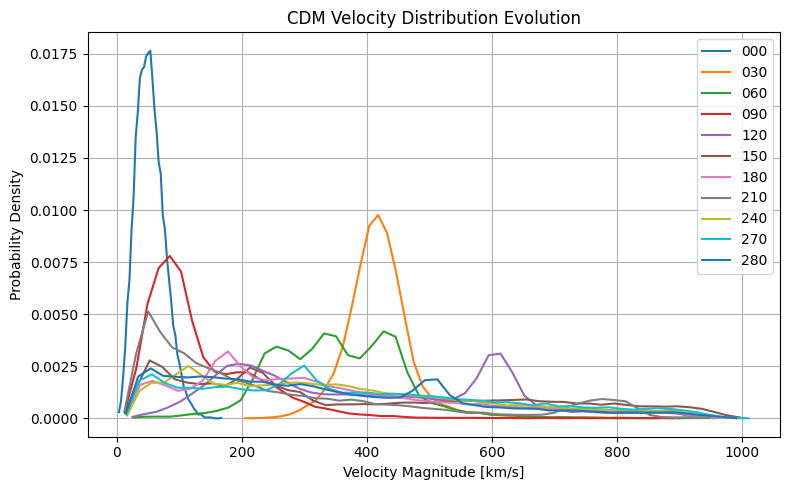

In [42]:
# velocity distribution evolution for CDM, plotted with interval + last snapshot

import os
import h5py
import numpy as np
import matplotlib.pyplot as plt

# ==================== CONFIGURATION ====================
AHF_DIR = "./Data/CDM_AHFout/"
SNAP_DIR = "./Data/CDM/"
SNAPSHOT_INTERVAL = 1

indices_to_process = list(range(0, 281, SNAPSHOT_INTERVAL))  # Process every 1st snapshot

plot_interval = 30

plt.figure(figsize=(8, 5))

for i in indices_to_process:
    snap_path = os.path.join(SNAP_DIR, f"snapshot_{i:03d}.hdf5")
    
    if os.path.exists(snap_path):
        with h5py.File(snap_path, 'r') as f:
            vel = f['PartType1/Velocities'][:]  # km/s
        
        vel_magnitude = np.linalg.norm(vel, axis=1)

        if i % plot_interval == 0 or i == 280:
            hist, bin_edges = np.histogram(vel_magnitude, bins=50, density=True)
            bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])

            plt.plot(bin_centers, hist, label=f'{i:03d}')

plt.xlabel('Velocity Magnitude [km/s]')
plt.ylabel('Probability Density')
plt.title('CDM Velocity Distribution Evolution')
plt.grid()
plt.legend()
plt.tight_layout()
plt.show()


## SIDM - Velocity distribution evolution ##

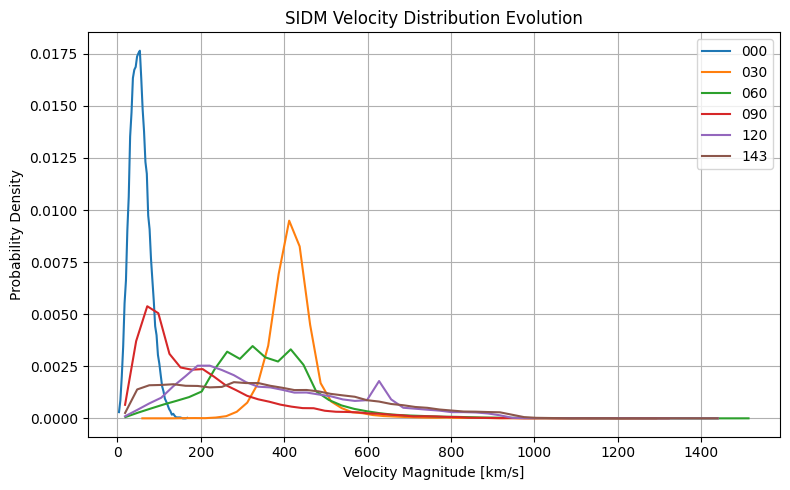

In [43]:
# velocity distribution evolution for SIDM, plotted with interval + last snapshot

import os
import h5py
import numpy as np
import matplotlib.pyplot as plt

# ==================== CONFIGURATION ====================
AHF_DIR = "./Data/SIDM_AHFout/"
SNAP_DIR = "./Data/SIDM/"
SNAPSHOT_INTERVAL = 1

indices_to_process = list(range(0, 144, SNAPSHOT_INTERVAL))  # Process every 1st snapshot

plot_interval = 30

plt.figure(figsize=(8, 5))

for i in indices_to_process:
    snap_path = os.path.join(SNAP_DIR, f"snapshot_{i:03d}.hdf5")
    
    if os.path.exists(snap_path):
        with h5py.File(snap_path, 'r') as f:
            vel = f['PartType1/Velocities'][:]  # km/s
        
        vel_magnitude = np.linalg.norm(vel, axis=1)

        if i % plot_interval == 0 or i == 143:
            hist, bin_edges = np.histogram(vel_magnitude, bins=50, density=True)
            bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])

            plt.plot(bin_centers, hist, label=f'{i:03d}')

plt.xlabel('Velocity Magnitude [km/s]')
plt.ylabel('Probability Density')
plt.title('SIDM Velocity Distribution Evolution')
plt.grid()
plt.legend()
plt.tight_layout()
plt.show()

## Stack several snapshot - Velocity distribution ##

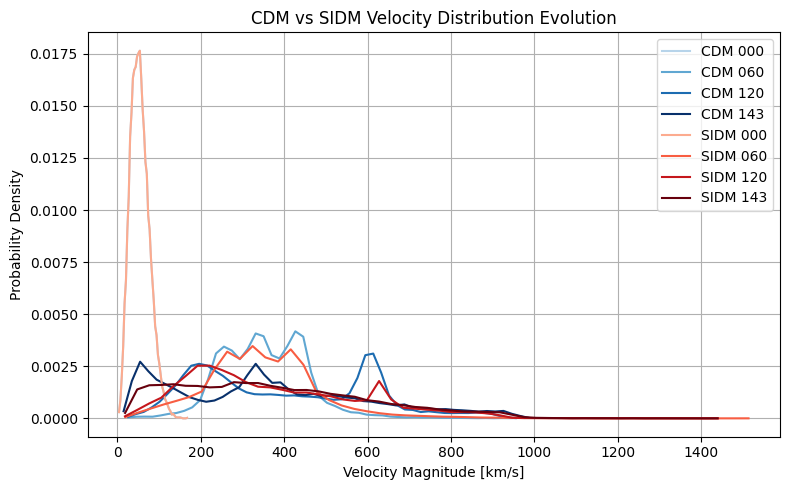

In [44]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt

# snapshot indices to plot for each model
CDM_plot_indices = [0, 60, 120, 143]
SIDM_plot_indices = [0, 60, 120, 143]

# ==================== CONFIGURATION ====================
SNAPSHOT_INTERVAL = 1

plt.figure(figsize=(8, 5))

# different color palettes for each model
cdm_cmap = plt.cm.Blues
sidm_cmap = plt.cm.Reds

cdm_colors = cdm_cmap(np.linspace(0.3, 1.0, len(CDM_plot_indices)))
sidm_colors = sidm_cmap(np.linspace(0.3, 1.0, len(SIDM_plot_indices)))

# ==================== CDM ====================
SNAP_DIR = "./Data/CDM/"
indices_to_process = list(range(0, 281, SNAPSHOT_INTERVAL))

for j, i in enumerate(CDM_plot_indices):
    snap_path = os.path.join(SNAP_DIR, f"snapshot_{i:03d}.hdf5")

    if os.path.exists(snap_path):
        with h5py.File(snap_path, 'r') as f:
            vel = f['PartType1/Velocities'][:]  # km/s

        vel_magnitude = np.linalg.norm(vel, axis=1)

        hist, bin_edges = np.histogram(vel_magnitude, bins=50, density=True)
        bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])

        plt.plot(bin_centers, hist, color=cdm_colors[j], label=f'CDM {i:03d}')

# ==================== SIDM ====================
SNAP_DIR = "./Data/SIDM/"
indices_to_process = list(range(0, 144, SNAPSHOT_INTERVAL))

for j, i in enumerate(SIDM_plot_indices):
    snap_path = os.path.join(SNAP_DIR, f"snapshot_{i:03d}.hdf5")

    if os.path.exists(snap_path):
        with h5py.File(snap_path, 'r') as f:
            vel = f['PartType1/Velocities'][:]  # km/s

        vel_magnitude = np.linalg.norm(vel, axis=1)

        hist, bin_edges = np.histogram(vel_magnitude, bins=50, density=True)
        bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])

        plt.plot(bin_centers, hist, color=sidm_colors[j], label=f'SIDM {i:03d}')

plt.xlabel('Velocity Magnitude [km/s]')
plt.ylabel('Probability Density')
plt.title('CDM vs SIDM Velocity Distribution Evolution')
plt.grid()
plt.legend()
plt.tight_layout()
plt.show()

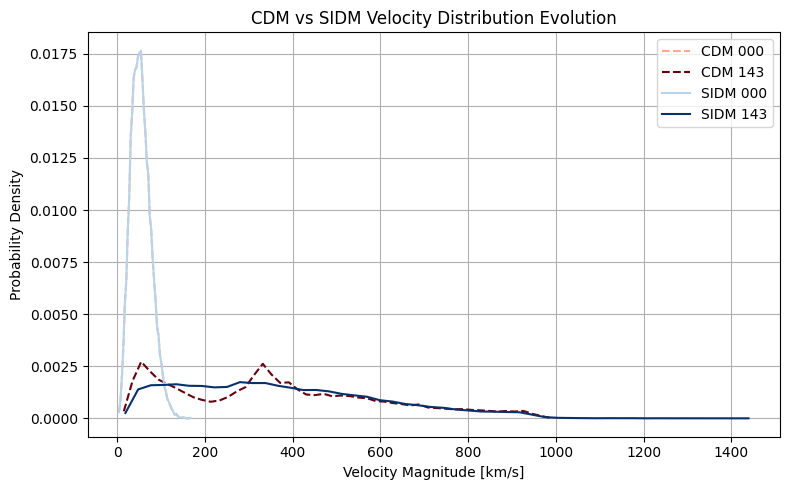

In [45]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt

# snapshot indices to plot for each model
CDM_plot_indices = [0, 143]
SIDM_plot_indices = [0, 143]

# ==================== CONFIGURATION ====================
SNAPSHOT_INTERVAL = 1

plt.figure(figsize=(8, 5))

# different color palettes for each model
cdm_cmap = plt.cm.Reds
sidm_cmap = plt.cm.Blues

cdm_colors = cdm_cmap(np.linspace(0.3, 1.0, len(CDM_plot_indices)))
sidm_colors = sidm_cmap(np.linspace(0.3, 1.0, len(SIDM_plot_indices)))

# ==================== CDM ====================
SNAP_DIR = "./Data/CDM/"
indices_to_process = list(range(0, 281, SNAPSHOT_INTERVAL))

for j, i in enumerate(CDM_plot_indices):
    snap_path = os.path.join(SNAP_DIR, f"snapshot_{i:03d}.hdf5")

    if os.path.exists(snap_path):
        with h5py.File(snap_path, 'r') as f:
            vel = f['PartType1/Velocities'][:]  # km/s

        vel_magnitude = np.linalg.norm(vel, axis=1)

        hist, bin_edges = np.histogram(vel_magnitude, bins=50, density=True)
        bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])

        plt.plot(bin_centers, hist, color=cdm_colors[j], label=f'CDM {i:03d}', linestyle='--')

# ==================== SIDM ====================
SNAP_DIR = "./Data/SIDM/"
indices_to_process = list(range(0, 144, SNAPSHOT_INTERVAL))

for j, i in enumerate(SIDM_plot_indices):
    snap_path = os.path.join(SNAP_DIR, f"snapshot_{i:03d}.hdf5")

    if os.path.exists(snap_path):
        with h5py.File(snap_path, 'r') as f:
            vel = f['PartType1/Velocities'][:]  # km/s

        vel_magnitude = np.linalg.norm(vel, axis=1)

        hist, bin_edges = np.histogram(vel_magnitude, bins=50, density=True)
        bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])

        plt.plot(bin_centers, hist, color=sidm_colors[j], label=f'SIDM {i:03d}')

plt.xlabel('Velocity Magnitude [km/s]')
plt.ylabel('Probability Density')
plt.title('CDM vs SIDM Velocity Distribution Evolution')
plt.grid()
plt.legend()
plt.tight_layout()
plt.show()